# 04. 생활입지 피처 엔지니어링

서울 아파트 거래 데이터에 생활입지 피처를 추가한다.

진행 순서:

1. 응급의료기관
2. 대규모점포
3. 일자리 입지

> 병원·대규모점포·일자리 피처를 모두 만든 뒤 `df_fe_living.parquet`으로 저장한다.

In [1]:
# ============================================================
# 라이브러리 및 기본 설정
# ============================================================

import os
import re
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

from dotenv import load_dotenv
from pyproj import Transformer
from sklearn.neighbors import BallTree

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

load_dotenv()

True

In [2]:
# ============================================================
# 경로 및 API 설정
# ============================================================

PROJECT_DIR = Path.cwd().parents[2]

DATA_ROOT = PROJECT_DIR / "data"
DATA_DIR = DATA_ROOT / "v2_5year_seoul"

PROCESSED_DIR = DATA_DIR / "processed"
EXTERNAL_DIR = DATA_ROOT / "external"

DF_FE_BASE_PATH = PROCESSED_DIR / "df_fe_base.parquet"
LIVING_FEATURE_PATH = PROCESSED_DIR / "df_fe_living.parquet"

EMERGENCY_API_KEY = os.environ.get("EMERGENCY_API_KEY", "")
KAKAO_REST_API_KEY = os.environ.get("KAKAO_REST_API_KEY", "")

missing_keys = [
    key_name
    for key_name, key_value in {
        "EMERGENCY_API_KEY": EMERGENCY_API_KEY,
        "KAKAO_REST_API_KEY": KAKAO_REST_API_KEY,
    }.items()
    if not key_value
]

if missing_keys:
    raise ValueError(
        f".env 파일에 API 키가 없습니다: {', '.join(missing_keys)}"
    )

HOSPITAL_API_URL = (
    "https://apis.data.go.kr/"
    "B552657/ErmctInfoInqireService/"
    "getEgytListInfoInqire"
)

print("PROJECT_DIR:", PROJECT_DIR.resolve())
print("API 키 로드 완료")

PROJECT_DIR: C:\Users\UK\Apartment price
API 키 로드 완료


## 공통 함수

시설 좌표 검증, 최근접 거리 계산, 주소 정리 및 카카오 지오코딩을 공통 함수로 관리한다.

In [3]:
# ============================================================
# 공통 함수
# ============================================================

EARTH_RADIUS_M = 6_371_000


def get_valid_seoul_coord_mask(
    df,
    lat_col="위도",
    lon_col="경도",
):
    return (
        df[lat_col].between(37.4, 37.8)
        & df[lon_col].between(126.7, 127.3)
    )


def get_nearest_facility(
    source_lat,
    source_lon,
    target_lat,
    target_lon,
):
    source_coords = np.radians(
        np.column_stack([source_lat, source_lon])
    )
    target_coords = np.radians(
        np.column_stack([target_lat, target_lon])
    )

    tree = BallTree(
        target_coords,
        metric="haversine",
    )

    distances, indices = tree.query(
        source_coords,
        k=1,
    )

    return (
        indices[:, 0],
        distances[:, 0] * EARTH_RADIUS_M,
    )


def clean_address(address):
    if pd.isna(address):
        return None

    address = str(address).strip()
    address = re.sub(r"\([^)]*\)", "", address)
    address = re.sub(r"\s+", " ", address)
    address = address.split(",")[0].strip()

    return address or None


def geocode_address(address, kakao_api_key):
    if not address:
        return None, None

    response = requests.get(
        "https://dapi.kakao.com/v2/local/search/address.json",
        headers={
            "Authorization": f"KakaoAK {kakao_api_key}",
        },
        params={
            "query": address,
        },
        timeout=10,
    )
    response.raise_for_status()

    documents = response.json().get("documents", [])

    if not documents:
        return None, None

    result = documents[0]

    return float(result["y"]), float(result["x"])


def geocode_keyword(keyword, kakao_api_key):
    response = requests.get(
        "https://dapi.kakao.com/v2/local/search/keyword.json",
        headers={
            "Authorization": f"KakaoAK {kakao_api_key}",
        },
        params={
            "query": keyword,
        },
        timeout=10,
    )
    response.raise_for_status()

    documents = response.json().get("documents", [])

    if not documents:
        return None, None

    seoul_documents = [
        doc
        for doc in documents
        if (
            str(doc.get("road_address_name", "")).startswith("서울")
            or str(doc.get("address_name", "")).startswith("서울")
        )
    ]

    result = (
        seoul_documents[0]
        if seoul_documents
        else documents[0]
    )

    return float(result["y"]), float(result["x"])

# 1. 응급의료기관

서울 응급의료기관을 수집·정제한 뒤 각 아파트 거래 위치에서 가장 가까운 응급의료기관까지의 거리를 계산한다.

In [4]:
# ============================================================
# 서울 응급의료기관 수집
# ============================================================

params = {
    "serviceKey": EMERGENCY_API_KEY,
    "Q0": "서울특별시",
    "pageNo": 1,
    "numOfRows": 1000,
}

response = requests.get(
    HOSPITAL_API_URL,
    params=params,
    timeout=30,
)
response.raise_for_status()

root = ET.fromstring(response.content)

result_code = root.findtext(".//resultCode")
result_message = root.findtext(".//resultMsg")
total_count = int(
    root.findtext(".//totalCount", default="0")
)

hospital_records = []

for item in root.findall(".//item"):
    hospital_records.append({
        "병원ID": item.findtext("hpid"),
        "병원명": item.findtext("dutyName"),
        "응급의료기관코드": item.findtext("dutyEmcls"),
        "응급의료기관분류": item.findtext("dutyEmclsName"),
        "주소": item.findtext("dutyAddr"),
        "위도": item.findtext("wgs84Lat"),
        "경도": item.findtext("wgs84Lon"),
    })

hospital_df = pd.DataFrame(hospital_records)

print("응답:", result_code, result_message)
print("API 기관 수:", total_count)
print("수집 행 수:", len(hospital_df))

응답: 00 NORMAL SERVICE.
API 기관 수: 74
수집 행 수: 74


In [5]:
# ============================================================
# 응급의료기관 정제 및 검증
# ============================================================

hospital_clean = hospital_df.copy()

hospital_clean["위도"] = pd.to_numeric(
    hospital_clean["위도"],
    errors="coerce",
)
hospital_clean["경도"] = pd.to_numeric(
    hospital_clean["경도"],
    errors="coerce",
)

hospital_clean = (
    hospital_clean
    .drop_duplicates(
        subset="병원ID",
        keep="last",
    )
    .reset_index(drop=True)
)

hospital_valid_coord = get_valid_seoul_coord_mask(
    hospital_clean
)

print("정제 후 병원 수:", len(hospital_clean))
print("정상 서울 좌표:", hospital_valid_coord.sum())
print("비정상·결측 좌표:", (~hospital_valid_coord).sum())

print("\n응급의료기관 분류:")
print(
    hospital_clean["응급의료기관분류"]
    .value_counts(dropna=False)
)

display(
    hospital_clean.loc[
        ~hospital_valid_coord,
        [
            "병원명",
            "주소",
            "위도",
            "경도",
        ],
    ]
)

정제 후 병원 수: 74
정상 서울 좌표: 74
비정상·결측 좌표: 0

응급의료기관 분류:
응급의료기관분류
지역응급의료센터     24
응급실운영신고기관    23
지역응급의료기관     20
권역응급의료센터      7
Name: count, dtype: int64


,병원명,주소,위도,경도


In [6]:
# ============================================================
# 기본 피처 데이터 불러오기
# ============================================================

df_living = pd.read_parquet(
    DF_FE_BASE_PATH
).copy()

apt_coord_mask = (
    df_living["위도"].notna()
    & df_living["경도"].notna()
)

print("거래 데이터:", df_living.shape)
print("아파트 좌표 결측:", (~apt_coord_mask).sum())

거래 데이터: (234302, 69)
아파트 좌표 결측: 0


In [7]:
# ============================================================
# 최근접 응급의료기관 피처 생성
# ============================================================

nearest_idx, nearest_distance = get_nearest_facility(
    df_living.loc[apt_coord_mask, "위도"].to_numpy(),
    df_living.loc[apt_coord_mask, "경도"].to_numpy(),
    hospital_clean["위도"].to_numpy(),
    hospital_clean["경도"].to_numpy(),
)

nearest_hospitals = (
    hospital_clean
    .iloc[nearest_idx]
    .reset_index(drop=True)
)

df_living.loc[
    apt_coord_mask,
    "최근접응급의료기관",
] = nearest_hospitals["병원명"].to_numpy()

df_living.loc[
    apt_coord_mask,
    "최근접응급의료기관분류",
] = nearest_hospitals["응급의료기관분류"].to_numpy()

df_living.loc[
    apt_coord_mask,
    "응급의료기관거리_m",
] = nearest_distance

df_living["응급의료기관거리_km"] = (
    df_living["응급의료기관거리_m"] / 1000
)

In [8]:
# ============================================================
# 응급의료기관 피처 최종 검증
# ============================================================

hospital_feature_cols = [
    "최근접응급의료기관",
    "최근접응급의료기관분류",
    "응급의료기관거리_m",
    "응급의료기관거리_km",
]

print("결측치:")
print(
    df_living[hospital_feature_cols]
    .isna()
    .sum()
)

print("\n거리 통계(km):")
print(
    df_living["응급의료기관거리_km"]
    .describe()
)

hospital_far_check = (
    df_living[
        [
            "법정동",
            "단지명",
            "최근접응급의료기관",
            "응급의료기관거리_km",
        ]
    ]
    .drop_duplicates(
        subset=["법정동", "단지명"]
    )
    .sort_values(
        "응급의료기관거리_km",
        ascending=False,
    )
    .head(10)
)

display(hospital_far_check)

결측치:
최근접응급의료기관      0
최근접응급의료기관분류    0
응급의료기관거리_m     0
응급의료기관거리_km    0
dtype: int64

거리 통계(km):
count    234302.000000
mean          1.239971
std           0.688347
min           0.029376
25%           0.732115
50%           1.164783
75%           1.624423
max           4.626382
Name: 응급의료기관거리_km, dtype: float64


,법정동,단지명,최근접응급의료기관,응급의료기관거리_km
59952,도봉동,서울가든,인제대학교상계백병원,4.626382
62326,도봉동,우영,인제대학교상계백병원,4.618906
60569,도봉동,도봉파크빌3,인제대학교상계백병원,4.524995
60345,도봉동,도봉산리베니움,인제대학교상계백병원,4.480405
63200,도봉동,삼안리치,인제대학교상계백병원,4.429016
59912,도봉동,한신,인제대학교상계백병원,4.402952
66962,상계동,수락리버시티3단지,인제대학교상계백병원,4.397924
186497,신원동,서초포레스타7단지,강남베드로병원,4.390206
140070,항동,항동제일풍경채포레스트,서울특별시서남병원,4.329716
181648,내곡동,서초더샵포레,강남베드로병원,4.304549


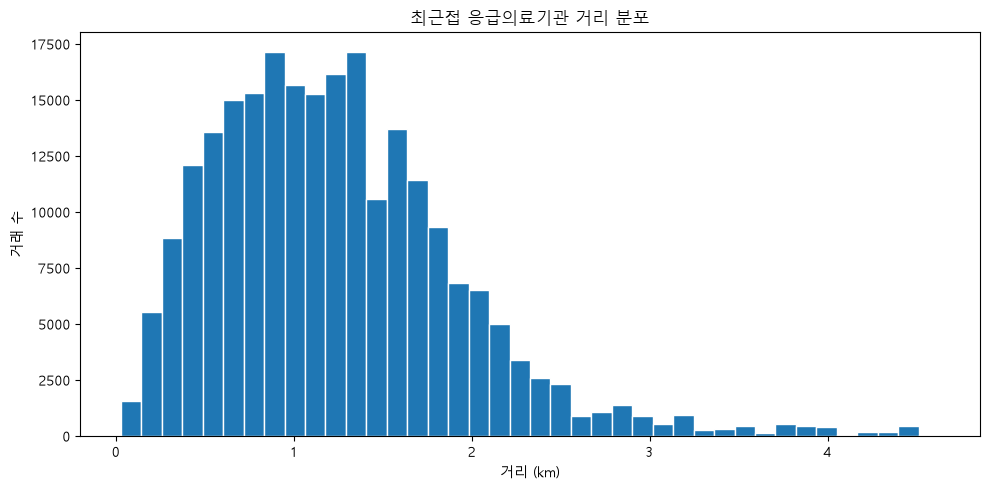

In [9]:
# ============================================================
# 응급의료기관 거리 분포
# ============================================================

plt.figure(figsize=(10, 5))

plt.hist(
    df_living["응급의료기관거리_km"],
    bins=40,
    edgecolor="white",
)

plt.title("최근접 응급의료기관 거리 분포")
plt.xlabel("거리 (km)")
plt.ylabel("거래 수")

plt.tight_layout()
plt.show()

### 응급의료기관 완료

생성 피처:

- `최근접응급의료기관`
- `최근접응급의료기관분류`
- `응급의료기관거리_m`
- `응급의료기관거리_km`

모델링에서는 단위가 중복되므로 `응급의료기관거리_km`를 주력 수치형 피처로 사용한다.

# 2. 대규모점포

현재 정상 영업 중인 서울 `대규모점포`를 기준으로 최근접 시설과 거리를 계산한다.

`업태구분명`은 분류 오류가 존재할 수 있으므로 필터 기준으로 사용하지 않고 메타데이터로 유지한다.

In [10]:
# ============================================================
# 대규모점포 원본 데이터 불러오기
# ============================================================

MART_RAW_PATH = (
    EXTERNAL_DIR
    / "large_scale_store.csv"
)

mart_raw = pd.read_csv(
    MART_RAW_PATH,
    encoding="cp949",
)

print("원본 크기:", mart_raw.shape)

for col in [
    "영업상태명",
    "상세영업상태명",
    "업태구분명",
    "점포구분명",
]:
    print(f"\n[{col}]")
    print(
        mart_raw[col]
        .value_counts(dropna=False)
    )

원본 크기: (1051, 26)

[영업상태명]
영업상태명
영업/정상             739
폐업                219
휴업                 81
취소/말소/만료/정지/중지     12
Name: count, dtype: int64

[상세영업상태명]
상세영업상태명
정상영업     713
폐업처리     219
휴업처리      81
영업개시전     18
직권취소      12
NaN        8
Name: count, dtype: int64

[업태구분명]
업태구분명
그 밖의 대규모점포    418
구분없음          262
대형마트          114
쇼핑센터           63
시장             63
복합쇼핑몰          57
백화점            37
전문점            34
NaN             3
Name: count, dtype: int64

[점포구분명]
점포구분명
대규모점포     523
준대규모점포    345
NaN       183
Name: count, dtype: int64


In [11]:
# ============================================================
# 서울 영업 중 대규모점포 추출
# ============================================================

seoul_mask = (
    mart_raw["도로명주소"].str.contains(
        "서울특별시",
        na=False,
    )
    | mart_raw["지번주소"].str.contains(
        "서울특별시",
        na=False,
    )
)

store_clean = (
    mart_raw.loc[
        seoul_mask
        & (mart_raw["영업상태명"] == "영업/정상")
        & (mart_raw["상세영업상태명"] == "정상영업")
        & (mart_raw["점포구분명"] == "대규모점포")
    ]
    .copy()
    .reset_index(drop=True)
)

print("서울 영업 중 대규모점포:", len(store_clean))

print("\n업태 분포:")
print(
    store_clean["업태구분명"]
    .value_counts(dropna=False)
)

서울 영업 중 대규모점포: 407

업태 분포:
업태구분명
그 밖의 대규모점포    211
대형마트           48
쇼핑센터           38
복합쇼핑몰          31
시장             27
전문점            25
백화점            25
구분없음            2
Name: count, dtype: int64


In [12]:
# ============================================================
# TM 좌표 → WGS84 변환
# EPSG:5174 → EPSG:4326
# ============================================================

store_clean["좌표정보(X)"] = pd.to_numeric(
    store_clean["좌표정보(X)"],
    errors="coerce",
)
store_clean["좌표정보(Y)"] = pd.to_numeric(
    store_clean["좌표정보(Y)"],
    errors="coerce",
)

transformer = Transformer.from_crs(
    "EPSG:5174",
    "EPSG:4326",
    always_xy=True,
)

source_coord_mask = (
    store_clean["좌표정보(X)"].notna()
    & store_clean["좌표정보(Y)"].notna()
)

lon, lat = transformer.transform(
    store_clean.loc[
        source_coord_mask,
        "좌표정보(X)",
    ].to_numpy(),
    store_clean.loc[
        source_coord_mask,
        "좌표정보(Y)",
    ].to_numpy(),
)

store_clean.loc[
    source_coord_mask,
    "경도",
] = lon

store_clean.loc[
    source_coord_mask,
    "위도",
] = lat

valid_store_coord = get_valid_seoul_coord_mask(
    store_clean
)

print("전체 점포:", len(store_clean))
print("정상 서울 좌표:", valid_store_coord.sum())
print("좌표 보완 대상:", (~valid_store_coord).sum())

전체 점포: 407
정상 서울 좌표: 398
좌표 보완 대상: 9


In [13]:
# ============================================================
# 비정상·결측 좌표 지오코딩 보완
# 주소 → 지번주소 → 사업장명 키워드 순서
# ============================================================

missing_idx = store_clean.index[
    ~get_valid_seoul_coord_mask(store_clean)
]

for idx in missing_idx:
    store_name = store_clean.loc[idx, "사업장명"]

    road_address = clean_address(
        store_clean.loc[idx, "도로명주소"]
    )
    jibun_address = clean_address(
        store_clean.loc[idx, "지번주소"]
    )

    lat, lon = None, None

    if road_address:
        lat, lon = geocode_address(
            road_address,
            KAKAO_REST_API_KEY,
        )

    if lat is None and jibun_address:
        lat, lon = geocode_address(
            jibun_address,
            KAKAO_REST_API_KEY,
        )

    if lat is None:
        lat, lon = geocode_keyword(
            f"서울 {store_name}",
            KAKAO_REST_API_KEY,
        )

    store_clean.loc[idx, "위도"] = lat
    store_clean.loc[idx, "경도"] = lon

## 대규모점포 시설 단위 정리

중복 인허가 레코드를 시설 단위로 정리한다.

- 동일 사업장명 + 동일 좌표는 최신 갱신 레코드만 유지
- 같은 사업장명·자치구에 정상 좌표 레코드가 있으면 좌표 결측 중복 레코드는 제외
- 수동 검증으로 확인한 주소 오류/현재 생활입지에 부적합한 레코드는 명시적으로 제외

In [14]:
# ============================================================
# 동일 시설 중복 정리
# ============================================================

address = (
    store_clean["도로명주소"]
    .fillna(store_clean["지번주소"])
)

store_clean["자치구"] = address.str.extract(
    r"서울특별시\s+(\S+구)"
)

before_rows = len(store_clean)

store_clean = (
    store_clean
    .sort_values(
        "데이터갱신시점",
        ascending=False,
    )
    .drop_duplicates(
        subset=[
            "사업장명",
            "위도",
            "경도",
        ],
        keep="first",
    )
    .reset_index(drop=True)
)

valid_name_district = (
    store_clean.loc[
        get_valid_seoul_coord_mask(store_clean),
        [
            "사업장명",
            "자치구",
        ],
    ]
    .drop_duplicates()
    .assign(동일시설_정상좌표존재=True)
)

store_clean = store_clean.merge(
    valid_name_district,
    on=[
        "사업장명",
        "자치구",
    ],
    how="left",
)

duplicate_missing_mask = (
    store_clean["동일시설_정상좌표존재"].eq(True)
    & ~get_valid_seoul_coord_mask(store_clean)
)

store_clean = (
    store_clean.loc[~duplicate_missing_mask]
    .drop(columns="동일시설_정상좌표존재")
    .reset_index(drop=True)
)

print("중복 정리 전:", before_rows)
print("중복 정리 후:", len(store_clean))

중복 정리 전: 407
중복 정리 후: 396


In [15]:
# ============================================================
# 수동 검증 결과 반영
# ============================================================

# 통일상가: 실제 통일상가가 아닌 주소로 연결된 중복 레코드
wrong_tongil_mask = (
    (store_clean["사업장명"] == "통일상가")
    & store_clean["도로명주소"].str.contains(
        "장충단로13길 20",
        na=False,
    )
)

# 공항시장: 현재 생활입지 시설로 사용하지 않기로 결정
airport_market_mask = (
    store_clean["사업장명"] == "(주)공항시장"
)

manual_exclude_mask = (
    wrong_tongil_mask
    | airport_market_mask
)

print("수동 제외:", manual_exclude_mask.sum())

display(
    store_clean.loc[
        manual_exclude_mask,
        [
            "사업장명",
            "업태구분명",
            "도로명주소",
            "지번주소",
        ],
    ]
)

store_clean = (
    store_clean.loc[~manual_exclude_mask]
    .reset_index(drop=True)
)

수동 제외: 2


,사업장명,업태구분명,도로명주소,지번주소
194,통일상가,그 밖의 대규모점포,서울특별시 중구 장충단로13길 20 (을지로6가),서울특별시 중구 을지로6가 17번지
346,(주)공항시장,시장,NaN,서울특별시 강서구 방화동 620호


In [16]:
# ============================================================
# 대규모점포 최종 품질 검증
# ============================================================

valid_store_coord = get_valid_seoul_coord_mask(
    store_clean
)

duplicate_store = store_clean.loc[
    store_clean["사업장명"].duplicated(
        keep=False
    ),
    [
        "사업장명",
        "업태구분명",
        "도로명주소",
        "위도",
        "경도",
    ],
]

print("최종 점포 수:", len(store_clean))
print("정상 서울 좌표:", valid_store_coord.sum())
print("비정상·결측 좌표:", (~valid_store_coord).sum())
print(
    "동일 사업장명 중복:",
    store_clean["사업장명"]
    .duplicated()
    .sum(),
)

display(
    store_clean.loc[
        ~valid_store_coord,
        [
            "사업장명",
            "도로명주소",
            "지번주소",
            "위도",
            "경도",
        ],
    ]
)

display(duplicate_store)

최종 점포 수: 394
정상 서울 좌표: 394
비정상·결측 좌표: 0
동일 사업장명 중복: 3


,사업장명,도로명주소,지번주소,위도,경도


,사업장명,업태구분명,도로명주소,위도,경도
191,대림상가,그 밖의 대규모점포,서울특별시 중구 을지로 157 (을지로4가),37.566758,126.995517
244,대림상가,그 밖의 대규모점포,서울특별시 서초구 나루터로 32 (잠원동),37.571675,126.993054
291,길음시장,그 밖의 대규모점포,NaN,37.602776,127.021936
309,길음시장,시장,서울특별시 성북구 동소문로 227 (길음동),37.602712,127.021767
351,길음시장,그 밖의 대규모점포,NaN,37.602712,127.021767


In [17]:
# ============================================================
# 최근접 대규모점포 피처 생성
# ============================================================

store_valid = (
    store_clean.loc[
        valid_store_coord,
        [
            "사업장명",
            "업태구분명",
            "위도",
            "경도",
        ],
    ]
    .reset_index(drop=True)
)

nearest_idx, nearest_distance = get_nearest_facility(
    df_living.loc[apt_coord_mask, "위도"].to_numpy(),
    df_living.loc[apt_coord_mask, "경도"].to_numpy(),
    store_valid["위도"].to_numpy(),
    store_valid["경도"].to_numpy(),
)

nearest_stores = (
    store_valid
    .iloc[nearest_idx]
    .reset_index(drop=True)
)

df_living.loc[
    apt_coord_mask,
    "최근접대규모점포",
] = nearest_stores["사업장명"].to_numpy()

df_living.loc[
    apt_coord_mask,
    "최근접대규모점포업태",
] = nearest_stores["업태구분명"].to_numpy()

df_living.loc[
    apt_coord_mask,
    "대규모점포거리_m",
] = nearest_distance

# 좌표 정밀도보다 작은 초근접 값은 0m로 정리
df_living.loc[
    df_living["대규모점포거리_m"] < 1,
    "대규모점포거리_m",
] = 0

df_living["대규모점포거리_km"] = (
    df_living["대규모점포거리_m"] / 1000
)

In [18]:
# ============================================================
# 대규모점포 피처 최종 검증
# ============================================================

store_feature_cols = [
    "최근접대규모점포",
    "최근접대규모점포업태",
    "대규모점포거리_m",
    "대규모점포거리_km",
]

print("결측치:")
print(
    df_living[store_feature_cols]
    .isna()
    .sum()
)

print("\n거리 통계(m):")
print(
    df_living["대규모점포거리_m"]
    .describe()
)

complex_store_distance = (
    df_living[
        [
            "법정동",
            "단지명",
            "최근접대규모점포",
            "최근접대규모점포업태",
            "대규모점포거리_m",
        ]
    ]
    .drop_duplicates(
        subset=["법정동", "단지명"]
    )
)

print("\n초근접 단지:")
display(
    complex_store_distance
    .sort_values("대규모점포거리_m")
    .head(10)
)

print("\n대규모점포에서 먼 단지:")
display(
    complex_store_distance
    .sort_values(
        "대규모점포거리_m",
        ascending=False,
    )
    .head(10)
)

결측치:
최근접대규모점포      0
최근접대규모점포업태    0
대규모점포거리_m     0
대규모점포거리_km    0
dtype: int64

거리 통계(m):
count    234302.000000
mean        621.203589
std         400.909706
min           0.000000
25%         343.740584
50%         548.411061
75%         833.438035
max        3492.928165
Name: 대규모점포거리_m, dtype: float64

초근접 단지:


,법정동,단지명,최근접대규모점포,최근접대규모점포업태,대규모점포거리_m
138012,구로동,신구로자이,나인스에비뉴,그 밖의 대규모점포,0.0
23,인의동,효성쥬얼리시티,효성주얼리시티,그 밖의 대규모점포,0.0
9941,도선동,삼성쉐르빌,성동삼성쉐르빌상가,그 밖의 대규모점포,0.0
88989,불광동,극동메트로타워,메트로,쇼핑센터,0.0
114475,목동,현대하이페리온,현대백화점목동점,백화점,0.0
174802,봉천동,보라매롯데캐슬,롯데쇼핑(주) 관악점,백화점,0.0
1532,창신동,동문상가,동문시장,시장,0.0
125139,화곡동,강서뉴타워,강서 뉴타워,그 밖의 대규모점포,0.0
191741,신사동,강남상가,강남시장,복합쇼핑몰,0.0
55935,수유동,수유삼호,수유프라자,그 밖의 대규모점포,0.0



대규모점포에서 먼 단지:


,법정동,단지명,최근접대규모점포,최근접대규모점포업태,대규모점포거리_m
140070,항동,항동제일풍경채포레스트,개봉제일시장,그 밖의 대규모점포,3492.928165
193,평창동,엘리시아,동소문스카이상가,그 밖의 대규모점포,3452.641279
150,평창동,롯데낙천대,동소문스카이상가,그 밖의 대규모점포,3442.329767
427,평창동,크래스빌,유진상가,시장,3438.306788
22,평창동,벽산블루밍평창힐스,유진상가,시장,3386.547349
172,평창동,일성빌라트,유진상가,시장,3370.117395
664,평창동,롯데캐슬로잔,동소문스카이상가,그 밖의 대규모점포,3354.998914
1930,평창동,형우럭스빌(33-1),유진상가,시장,3318.167353
57,평창동,삼성,동소문스카이상가,그 밖의 대규모점포,3314.376578
139388,온수동,두양그린B동,개봉프라자,시장,3212.637532


### 대규모점포 완료

생성 피처:

- `최근접대규모점포`
- `최근접대규모점포업태`
- `대규모점포거리_m`
- `대규모점포거리_km`

모델링에서는 `대규모점포거리_km`를 주력 수치형 피처로 사용한다.

# 3. 일자리 입지

다음 단계에서 업무지역 접근성 또는 직장인구 기반 피처를 추가한다.

> 일자리 입지까지 완료한 뒤 `transaction_id`와 생활입지 피처만 선택하여 `df_fe_living.parquet`으로 저장한다.

In [20]:
# ============================================================
# 직장인구 데이터 불러오기
# ============================================================

WORKPLACE_PATH = (
    EXTERNAL_DIR
    / "workplace_population.csv"
)

workplace_raw = pd.read_csv(
    WORKPLACE_PATH,
    encoding="cp949",
)

print("데이터 크기:", workplace_raw.shape)

print("\n컬럼:")
print(workplace_raw.columns.tolist())

display(workplace_raw.head())

데이터 크기: (8694, 24)

컬럼:
['기준_년분기_코드', '행정동_코드', '행정동_코드_명', '총_직장_인구_수', '남성_직장_인구_수', '여성_직장_인구_수', '연령대_10_직장_인구_수', '연령대_20_직장_인구_수', '연령대_30_직장_인구_수', '연령대_40_직장_인구_수', '연령대_50_직장_인구_수', '연령대_60_이상_직장_인구_수', '남성연령대_10_직장_인구_수', '남성연령대_20_직장_인구_수', '남성연령대_30_직장_인구_수', '남성연령대_40_직장_인구_수', '남성연령대_50_직장_인구_수', '남성연령대_60_이상_직장_인구_수', '여성연령대_10_직장_인구_수', '여성연령대_20_직장_인구_수', '여성연령대_30_직장_인구_수', '여성연령대_40_직장_인구_수', '여성연령대_50_직장_인구_수', '여성연령대_60_이상_직장_인구_수']


,기준_년분기_코드,행정동_코드,행정동_코드_명,총_직장_인구_수,남성_직장_인구_수,여성_직장_인구_수,연령대_10_직장_인구_수,연령대_20_직장_인구_수,연령대_30_직장_인구_수,연령대_40_직장_인구_수,...,남성연령대_30_직장_인구_수,남성연령대_40_직장_인구_수,남성연령대_50_직장_인구_수,남성연령대_60_이상_직장_인구_수,여성연령대_10_직장_인구_수,여성연령대_20_직장_인구_수,여성연령대_30_직장_인구_수,여성연령대_40_직장_인구_수,여성연령대_50_직장_인구_수,여성연령대_60_이상_직장_인구_수
0,20261,11680670,개포2동,8854,5812,3042,2,1555,2526,2126,...,1691,1463,1050,777,2,724,835,663,593,225
1,20261,11710562,방이2동,40697,23384,17313,0,6579,10448,9191,...,6803,5625,4074,3187,0,2884,3645,3566,4618,2600
2,20261,11680700,세곡동,379,233,146,0,5,66,79,...,35,48,76,74,0,5,31,31,48,31
3,20261,11680590,삼성2동,70662,40645,30017,44,14269,22959,17969,...,13510,12008,5622,3576,33,8351,9449,5961,4388,1835
4,20261,11650510,서초1동,47656,26664,20992,0,10020,12365,10535,...,6646,6099,8061,2259,0,6421,5719,4436,3578,838


In [21]:
# ============================================================
# 직장인구 데이터 기간 확인
# ============================================================

workplace_raw["기준_년분기_코드"] = (
    workplace_raw["기준_년분기_코드"]
    .astype(str)
)

workplace_raw["기준연도"] = (
    workplace_raw["기준_년분기_코드"]
    .str[:4]
    .astype(int)
)

workplace_raw["기준분기"] = (
    workplace_raw["기준_년분기_코드"]
    .str[-1]
    .astype(int)
)

periods = sorted(
    workplace_raw["기준_년분기_코드"].unique()
)

print("최초 분기:", periods[0])
print("최신 분기:", periods[-1])
print("분기 수:", len(periods))
print(periods)

최초 분기: 20211
최신 분기: 20261
분기 수: 21
['20211', '20212', '20213', '20214', '20221', '20222', '20223', '20224', '20231', '20232', '20233', '20234', '20241', '20242', '20243', '20244', '20251', '20252', '20253', '20254', '20261']


In [22]:
# ============================================================
# 직장인구 데이터 기본 품질 검증
# ============================================================

key_cols = [
    "기준_년분기_코드",
    "행정동_코드",
]

check_cols = [
    "기준_년분기_코드",
    "행정동_코드",
    "행정동_코드_명",
    "총_직장_인구_수",
]

print(
    "중복 키:",
    workplace_raw
    .duplicated(key_cols)
    .sum(),
)

print("\n결측치:")
print(
    workplace_raw[
        check_cols
    ].isna().sum()
)

print("\n분기별 행정동 수:")
print(
    workplace_raw
    .groupby("기준_년분기_코드")["행정동_코드"]
    .nunique()
)

중복 키: 0

결측치:
기준_년분기_코드    0
행정동_코드       0
행정동_코드_명     0
총_직장_인구_수    0
dtype: int64

분기별 행정동 수:
기준_년분기_코드
20211    414
20212    414
20213    414
20214    414
20221    414
20222    414
20223    414
20224    414
20231    414
20232    414
20233    414
20234    414
20241    414
20242    414
20243    414
20244    414
20251    414
20252    414
20253    414
20254    414
20261    414
Name: 행정동_코드, dtype: int64


In [23]:
# ============================================================
# 거래 데이터 행정동 관련 컬럼 확인
# ============================================================

location_cols = [
    col
    for col in df_living.columns
    if any(
        keyword in col
        for keyword in [
            "행정동",
            "법정동",
            "년",
            "월",
            "계약",
            "거래",
        ]
    )
]

print(location_cols)

['법정동시군구코드', '법정동읍면동코드', '법정동지번코드', '법정동본번코드', '법정동부번코드', '법정동', '계약년도', '계약월', '계약일', '거래금액', '건축년도', '거래유형', '거래연월', '계약일자', '거래년도', '거래월', '거래월일자', '경과월', '월_sin', '월_cos', '구_전월_중위가격', '구_전월_중위평당가', '구_전월_거래량', '구_과거3개월_중위가격', '구_과거6개월_중위가격', '구_과거3개월_거래량', '구_과거6개월_거래량', '구_전월_가격변화율', '서울_전월_중위가격', '서울_과거3개월_중위가격', '서울_과거6개월_중위가격', '서울_전월_거래량', '서울_과거3개월_거래량', '서울_전월_가격변화율']


In [24]:
# ============================================================
# 행정동 매칭용 고유 아파트 좌표 추출
# ============================================================

apt_locations = (
    df_living[
        [
            "위도",
            "경도",
        ]
    ]
    .drop_duplicates()
    .dropna()
    .reset_index(drop=True)
)

print("전체 거래 수:", len(df_living))
print("고유 좌표 수:", len(apt_locations))

display(
    apt_locations.head()
)

전체 거래 수: 234302
고유 좌표 수: 7820


,위도,경도
0,37.575631,126.961060
1,37.574417,126.968881
2,37.570696,126.963609
3,37.572614,126.972273
4,37.580323,127.011785


In [25]:
# ============================================================
# Kakao 좌표 → 행정동 조회
# ============================================================

def get_admin_dong(
    lat,
    lon,
    kakao_api_key,
):
    url = (
        "https://dapi.kakao.com/"
        "v2/local/geo/coord2regioncode.json"
    )

    headers = {
        "Authorization":
        f"KakaoAK {kakao_api_key}",
    }

    params = {
        "x": lon,
        "y": lat,
    }

    response = requests.get(
        url,
        headers=headers,
        params=params,
        timeout=10,
    )

    response.raise_for_status()

    documents = response.json().get(
        "documents",
        []
    )

    # H = 행정동
    admin_region = next(
        (
            doc
            for doc in documents
            if doc["region_type"] == "H"
        ),
        None,
    )

    if admin_region is None:
        return None, None

    return (
        admin_region["code"],
        admin_region["region_3depth_name"],
    )

In [26]:
# ============================================================
# 행정동 코드 형식 확인
# ============================================================

test_lat = apt_locations.loc[0, "위도"]
test_lon = apt_locations.loc[0, "경도"]

test_code, test_name = get_admin_dong(
    test_lat,
    test_lon,
    KAKAO_REST_API_KEY,
)

print("행정동 코드:", test_code)
print("행정동명:", test_name)
print("코드 길이:", len(test_code))

행정동 코드: 1111057000
행정동명: 무악동
코드 길이: 10


In [27]:
# ============================================================
# Kakao 행정동 코드 ↔ 직장인구 코드 검증
# ============================================================

test_workplace_code = test_code[:8]

print("Kakao 코드:", test_code)
print("변환 코드:", test_workplace_code)
print("Kakao 행정동명:", test_name)

display(
    workplace_raw.loc[
        workplace_raw["행정동_코드"]
        .astype(str)
        .eq(test_workplace_code),
        [
            "행정동_코드",
            "행정동_코드_명",
        ],
    ]
    .drop_duplicates()
)

Kakao 코드: 1111057000
변환 코드: 11110570
Kakao 행정동명: 무악동


,행정동_코드,행정동_코드_명
53,11110570,무악동


In [28]:
# ============================================================
# 고유 아파트 좌표 → 행정동 매칭
# ============================================================

from time import sleep


admin_results = []

for i, row in apt_locations.iterrows():
    try:
        admin_code, admin_name = get_admin_dong(
            row["위도"],
            row["경도"],
            KAKAO_REST_API_KEY,
        )

        admin_results.append({
            "위도": row["위도"],
            "경도": row["경도"],
            "행정동_코드": (
                admin_code[:8]
                if admin_code
                else None
            ),
            "행정동명": admin_name,
        })

    except Exception as e:
        admin_results.append({
            "위도": row["위도"],
            "경도": row["경도"],
            "행정동_코드": None,
            "행정동명": None,
        })

        print(
            f"실패 {i}:",
            row["위도"],
            row["경도"],
            e,
        )

    if (i + 1) % 500 == 0:
        print(
            f"{i + 1:,} / {len(apt_locations):,} 완료"
        )
        sleep(0.2)


apt_admin = pd.DataFrame(
    admin_results
)

print("\n매칭 결과:", len(apt_admin))
print(
    "행정동 결측:",
    apt_admin["행정동_코드"]
    .isna()
    .sum(),
)

display(
    apt_admin.head()
)

500 / 7,820 완료
1,000 / 7,820 완료
1,500 / 7,820 완료
2,000 / 7,820 완료
2,500 / 7,820 완료
3,000 / 7,820 완료
3,500 / 7,820 완료
4,000 / 7,820 완료
4,500 / 7,820 완료
5,000 / 7,820 완료
5,500 / 7,820 완료
6,000 / 7,820 완료
6,500 / 7,820 완료
7,000 / 7,820 완료
7,500 / 7,820 완료

매칭 결과: 7820
행정동 결측: 0


,위도,경도,행정동_코드,행정동명
0,37.575631,126.961060,11110570,무악동
1,37.574417,126.968881,11110530,사직동
2,37.570696,126.963609,11110580,교남동
3,37.572614,126.972273,11110530,사직동
4,37.580323,127.011785,11110690,창신3동


In [29]:
# ============================================================
# 행정동 매칭 품질 검증
# ============================================================

print("고유 아파트 위치:", len(apt_admin))

print(
    "행정동 코드 결측:",
    apt_admin["행정동_코드"].isna().sum(),
)

print(
    "매칭된 행정동 수:",
    apt_admin["행정동_코드"].nunique(),
)

workplace_codes = set(
    workplace_raw["행정동_코드"]
    .astype(str)
    .unique()
)

matched_mask = (
    apt_admin["행정동_코드"]
    .astype(str)
    .isin(workplace_codes)
)

print(
    "직장인구 코드와 매칭:",
    matched_mask.sum(),
)

print(
    "직장인구 코드와 미매칭:",
    (~matched_mask).sum(),
)

고유 아파트 위치: 7820
행정동 코드 결측: 0
매칭된 행정동 수: 425
직장인구 코드와 매칭: 7698
직장인구 코드와 미매칭: 122


In [30]:
# ============================================================
# 직장인구 코드 미매칭 행정동 확인
# ============================================================

workplace_codes = set(
    workplace_raw["행정동_코드"]
    .astype(str)
    .unique()
)

unmatched_admin = (
    apt_admin.loc[
        ~apt_admin["행정동_코드"]
        .astype(str)
        .isin(workplace_codes)
    ]
    .copy()
)

unmatched_summary = (
    unmatched_admin
    .groupby(
        [
            "행정동_코드",
            "행정동명",
        ],
        as_index=False,
    )
    .size()
    .sort_values(
        "size",
        ascending=False,
    )
)

print("미매칭 고유 좌표:", len(unmatched_admin))
print(
    "미매칭 행정동 종류:",
    unmatched_summary["행정동_코드"].nunique(),
)

display(unmatched_summary)

미매칭 고유 좌표: 122
미매칭 행정동 종류: 15


,행정동_코드,행정동명,size
5,11530520,구로1동,17
1,11230533,용두동,14
0,11230515,신설동,13
13,11740590,암사3동,13
9,11710647,위례동,13
6,11530800,항동,10
8,11680720,일원본동,9
11,11740525,상일1동,8
7,11680675,개포3동,7
3,11470670,신정6동,5


In [31]:
# ============================================================
# 동일 행정동명이 다른 코드로 존재하는지 확인
# ============================================================

workplace_lookup = (
    workplace_raw[
        [
            "행정동_코드",
            "행정동_코드_명",
        ]
    ]
    .drop_duplicates()
    .copy()
)

workplace_lookup["행정동_코드"] = (
    workplace_lookup["행정동_코드"]
    .astype(str)
)

unmatched_summary["직장인구_동명존재"] = (
    unmatched_summary["행정동명"]
    .isin(
        workplace_lookup["행정동_코드_명"]
    )
)

display(
    unmatched_summary[
        [
            "행정동_코드",
            "행정동명",
            "size",
            "직장인구_동명존재",
        ]
    ]
)

,행정동_코드,행정동명,size,직장인구_동명존재
5,11530520,구로1동,17,False
1,11230533,용두동,14,False
0,11230515,신설동,13,False
13,11740590,암사3동,13,False
9,11710647,위례동,13,False
6,11530800,항동,10,False
8,11680720,일원본동,9,False
11,11740525,상일1동,8,False
7,11680675,개포3동,7,False
3,11470670,신정6동,5,False


In [32]:
# ============================================================
# 상권분석서비스 영역-행정동 데이터 확인
# ============================================================

ADMIN_AREA_PATH = (
    EXTERNAL_DIR
    / "서울시 상권분석서비스(영역-행정동).csv"
)

admin_area_raw = pd.read_csv(
    ADMIN_AREA_PATH,
    encoding="cp949",
)

print("데이터 크기:", admin_area_raw.shape)

print("\n컬럼:")
print(admin_area_raw.columns.tolist())

display(admin_area_raw.head())

데이터 크기: (425, 5)

컬럼:
['행정동_코드', '행정동_명', '엑스좌표_값', '와이좌표_값', '영역_면적']


,행정동_코드,행정동_명,엑스좌표_값,와이좌표_값,영역_면적
0,11140520,소공동,197736,451636,943795
1,11110515,청운효자동,197342,453874,2568432
2,11110530,사직동,197383,452705,1158536
3,11110540,삼청동,198340,454312,1479255
4,11110550,부암동,196781,455266,2274739


In [33]:
# ============================================================
# 행정동 영역 데이터 검증
# ============================================================

admin_area_raw["행정동_코드"] = (
    admin_area_raw["행정동_코드"]
    .astype(str)
)

workplace_codes = set(
    workplace_raw["행정동_코드"]
    .astype(str)
)

area_codes = set(
    admin_area_raw["행정동_코드"]
)

print("영역 행정동 수:", len(admin_area_raw))
print(
    "영역 행정동 고유 코드:",
    admin_area_raw["행정동_코드"].nunique(),
)

print(
    "직장인구와 공통 코드:",
    len(area_codes & workplace_codes),
)

print(
    "영역에만 존재:",
    len(area_codes - workplace_codes),
)

print(
    "직장인구에만 존재:",
    len(workplace_codes - area_codes),
)

영역 행정동 수: 425
영역 행정동 고유 코드: 425
직장인구와 공통 코드: 414
영역에만 존재: 11
직장인구에만 존재: 0


In [34]:
# ============================================================
# 영역 데이터에만 존재하는 행정동 확인
# ============================================================

area_only = (
    admin_area_raw.loc[
        ~admin_area_raw["행정동_코드"]
        .isin(workplace_codes),
        [
            "행정동_코드",
            "행정동_명",
            "엑스좌표_값",
            "와이좌표_값",
            "영역_면적",
        ],
    ]
    .sort_values("행정동_코드")
    .reset_index(drop=True)
)

print("영역 데이터에만 존재:", len(area_only))

display(area_only)

영역 데이터에만 존재: 11


,행정동_코드,행정동_명,엑스좌표_값,와이좌표_값,영역_면적
0,11350612,하계2동,205734,459495,500023
1,11470670,신정6동,188487,446275,940885
2,11500604,가양2동,187133,451925,823874
3,11530520,구로1동,188981,443750,1008892
4,11530800,항동,184486,442414,1446941
5,11680720,일원본동,207478,442544,2354625
6,11680740,일원2동,206971,444095,1300290
7,11710647,위례동,212445,442428,2537372
8,11710720,잠실7동,206533,445319,723486
9,11740590,암사3동,212249,451304,1799368


In [35]:
# ============================================================
# 카카오 미매칭 행정동과 영역 데이터 비교
# ============================================================

unmatched_compare = (
    unmatched_summary.merge(
        admin_area_raw[
            [
                "행정동_코드",
                "행정동_명",
            ]
        ],
        on="행정동_코드",
        how="left",
    )
)

unmatched_compare["영역데이터_존재"] = (
    unmatched_compare["행정동_명"].notna()
)

display(
    unmatched_compare[
        [
            "행정동_코드",
            "행정동명",
            "size",
            "영역데이터_존재",
            "행정동_명",
        ]
    ]
)

,행정동_코드,행정동명,size,영역데이터_존재,행정동_명
0,11530520,구로1동,17,True,구로1동
1,11230533,용두동,14,False,NaN
2,11230515,신설동,13,False,NaN
3,11740590,암사3동,13,True,암사3동
4,11710647,위례동,13,True,위례동
5,11530800,항동,10,True,항동
6,11680720,일원본동,9,True,일원본동
7,11740525,상일1동,8,False,NaN
8,11680675,개포3동,7,False,NaN
9,11470670,신정6동,5,True,신정6동


In [40]:
# ============================================================
# 행정동 개편 이전 코드 확인
# ============================================================

legacy_names = [
    "용신동",
    "일원2동",
    "상일동",
    "강일동",
]

legacy_lookup = (
    workplace_raw[
        [
            "행정동_코드",
            "행정동_코드_명",
        ]
    ]
    .drop_duplicates()
)

display(
    legacy_lookup.loc[
        legacy_lookup["행정동_코드_명"]
        .isin(legacy_names)
    ]
    .sort_values("행정동_코드_명")
)

,행정동_코드,행정동_코드_명
47,11740515,강일동
292,11740520,상일동
362,11230536,용신동


In [41]:
# ============================================================
# 직장인구 기준 행정동 코드 보정
# ============================================================

workplace_codes = set(
    workplace_raw["행정동_코드"]
    .astype(str)
)

legacy_code_map = (
    workplace_raw[
        [
            "행정동_코드",
            "행정동_코드_명",
        ]
    ]
    .drop_duplicates()
    .assign(
        행정동_코드=lambda x:
        x["행정동_코드"].astype(str)
    )
    .set_index("행정동_코드_명")["행정동_코드"]
    .to_dict()
)

# 에러가 난 이전 실행 결과를 제거하고 처음부터 시작
apt_admin["직장인구_행정동_코드"] = (
    apt_admin["행정동_코드"]
    .astype(str)
)

confirmed_mapping = {
    "용두동": "용신동",
    "신설동": "용신동",
    "상일1동": "상일동",
    "상일2동": "강일동",
}

for current_name, workplace_name in confirmed_mapping.items():

    target_code = legacy_code_map[workplace_name]

    mask = (
        apt_admin["행정동명"].eq(current_name)
        & ~apt_admin["직장인구_행정동_코드"]
        .isin(workplace_codes)
    )

    apt_admin.loc[
        mask,
        "직장인구_행정동_코드",
    ] = target_code

In [42]:
# ============================================================
# 행정동 코드 보정 결과 검증
# ============================================================

matched_mask = (
    apt_admin["직장인구_행정동_코드"]
    .isin(workplace_codes)
)

print("전체 고유 위치:", len(apt_admin))
print("직장인구 코드 매칭:", matched_mask.sum())
print("미매칭:", (~matched_mask).sum())

remaining_unmatched = (
    apt_admin.loc[
        ~matched_mask,
        [
            "행정동_코드",
            "행정동명",
        ],
    ]
    .groupby(
        [
            "행정동_코드",
            "행정동명",
        ],
        as_index=False,
    )
    .size()
    .sort_values(
        "size",
        ascending=False,
    )
)

display(remaining_unmatched)

전체 고유 위치: 7820
직장인구 코드 매칭: 7735
미매칭: 85


,행정동_코드,행정동명,size
3,11530520,구로1동,17
7,11710647,위례동,13
9,11740590,암사3동,13
4,11530800,항동,10
6,11680720,일원본동,9
5,11680675,개포3동,7
1,11470670,신정6동,5
2,11500604,가양2동,4
0,11350612,하계2동,4
8,11710720,잠실7동,2


In [43]:
# ============================================================
# 행정동 미매칭 거래 건수 확인
# ============================================================

admin_map = apt_admin[
    [
        "위도",
        "경도",
        "행정동명",
        "직장인구_행정동_코드",
    ]
].copy()

df_work = df_living.merge(
    admin_map,
    on=["위도", "경도"],
    how="left",
    validate="many_to_one",
)

workplace_codes = set(
    workplace_raw["행정동_코드"]
    .astype(str)
)

workplace_match_mask = (
    df_work["직장인구_행정동_코드"]
    .isin(workplace_codes)
)

unmatched_count = (~workplace_match_mask).sum()
unmatched_rate = (
    unmatched_count / len(df_work) * 100
)

print("전체 거래:", len(df_work))
print("직장인구 코드 매칭:", workplace_match_mask.sum())
print("미매칭 거래:", unmatched_count)
print(f"미매칭 비율: {unmatched_rate:.2f}%")

전체 거래: 234302
직장인구 코드 매칭: 227122
미매칭 거래: 7180
미매칭 비율: 3.06%


In [44]:
# ============================================================
# 미매칭 거래의 행정동별 분포
# ============================================================

unmatched_transactions = (
    df_work.loc[
        ~workplace_match_mask
    ]
    .groupby(
        [
            "직장인구_행정동_코드",
            "행정동명",
        ],
        as_index=False,
    )
    .size()
    .sort_values(
        "size",
        ascending=False,
    )
)

display(unmatched_transactions)

,직장인구_행정동_코드,행정동명,size
3,11530520,구로1동,950
0,11350612,하계2동,947
6,11680720,일원본동,943
7,11710647,위례동,895
5,11680675,개포3동,800
9,11740590,암사3동,757
1,11470670,신정6동,636
2,11500604,가양2동,460
4,11530800,항동,447
8,11710720,잠실7동,237


In [45]:
# ============================================================
# 거래 시점 기준 직전 분기 생성
# ============================================================

def get_workplace_period(year, month):
    quarter = (month - 1) // 3 + 1

    if quarter == 1:
        prev_year = year - 1
        prev_quarter = 4
    else:
        prev_year = year
        prev_quarter = quarter - 1

    period = int(
        f"{prev_year}{prev_quarter}"
    )

    # 직장인구 데이터 가용 범위
    period = max(period, 20211)
    period = min(period, 20261)

    return str(period)


df_work["직장인구_기준분기"] = [
    get_workplace_period(year, month)
    for year, month in zip(
        df_work["거래년도"],
        df_work["거래월"],
    )
]

print(
    df_work["직장인구_기준분기"]
    .value_counts()
    .sort_index()
)

직장인구_기준분기
20212    11427
20213     4686
20214     3398
20221     4520
20222     2008
20223     2121
20224     6864
20231    10409
20232    10835
20233     5926
20234     9460
20241    17202
20242    18281
20243    10231
20244    19502
20251    24075
20252    17091
20253    16697
20254    16683
20261    22886
Name: count, dtype: int64


In [48]:
# ============================================================
# 직장인구 결합 및 자치구 중앙값 보완
# ============================================================

workplace = workplace_raw[
    [
        "기준_년분기_코드",
        "행정동_코드",
        "총_직장_인구_수",
    ]
].copy()

workplace["기준_년분기_코드"] = (
    workplace["기준_년분기_코드"]
    .astype(str)
)

workplace["행정동_코드"] = (
    workplace["행정동_코드"]
    .astype(str)
)

# 자치구 코드는 행정동 코드 앞 5자리
workplace["자치구_코드"] = (
    workplace["행정동_코드"]
    .str[:5]
)

df_work["자치구_코드"] = (
    df_work["직장인구_행정동_코드"]
    .astype(str)
    .str[:5]
)

# 행정동별 직장인구 결합
df_work = df_work.merge(
    workplace[
        [
            "기준_년분기_코드",
            "행정동_코드",
            "총_직장_인구_수",
        ]
    ],
    left_on=[
        "직장인구_기준분기",
        "직장인구_행정동_코드",
    ],
    right_on=[
        "기준_년분기_코드",
        "행정동_코드",
    ],
    how="left",
    validate="many_to_one",
)

# 보완 대상 표시
df_work["직장인구_보완여부"] = (
    df_work["총_직장_인구_수"]
    .isna()
    .astype(int)
)

# 분기 × 자치구별 직장인구 중앙값
district_median = (
    workplace
    .groupby(
        [
            "기준_년분기_코드",
            "자치구_코드",
        ],
        as_index=False,
    )["총_직장_인구_수"]
    .median()
    .rename(
        columns={
            "총_직장_인구_수":
            "자치구_직장인구_중앙값"
        }
    )
)

df_work = df_work.merge(
    district_median,
    left_on=[
        "직장인구_기준분기",
        "자치구_코드",
    ],
    right_on=[
        "기준_년분기_코드",
        "자치구_코드",
    ],
    how="left",
    suffixes=("", "_district"),
    validate="many_to_one",
)

# 미매칭 행정동은 같은 자치구·분기 중앙값으로 보완
df_work["총_직장_인구_수"] = (
    df_work["총_직장_인구_수"]
    .fillna(
        df_work["자치구_직장인구_중앙값"]
    )
)

print("전체 거래:", len(df_work))

print(
    "보완 거래:",
    df_work["직장인구_보완여부"].sum(),
)

print(
    "최종 결측:",
    df_work["총_직장_인구_수"]
    .isna()
    .sum(),
)

전체 거래: 234302
보완 거래: 7180
최종 결측: 0


In [49]:
# ============================================================
# 직장인구 밀도 생성
# ============================================================

area_lookup = admin_area_raw[
    [
        "행정동_코드",
        "영역_면적",
    ]
].copy()

area_lookup["행정동_코드"] = (
    area_lookup["행정동_코드"]
    .astype(str)
)

# 직장인구 데이터에 행정동 면적 결합
workplace_density = workplace.merge(
    area_lookup,
    on="행정동_코드",
    how="left",
    validate="many_to_one",
)

# 영역_면적: m² → km²
workplace_density["행정동_면적_km2"] = (
    workplace_density["영역_면적"]
    / 1_000_000
)

# 1km²당 직장인구
workplace_density["직장인구밀도_명_km2"] = (
    workplace_density["총_직장_인구_수"]
    / workplace_density["행정동_면적_km2"]
)

print(
    "면적 결측:",
    workplace_density["행정동_면적_km2"]
    .isna()
    .sum(),
)

print(
    "밀도 결측:",
    workplace_density["직장인구밀도_명_km2"]
    .isna()
    .sum(),
)

display(
    workplace_density[
        [
            "행정동_코드",
            "총_직장_인구_수",
            "행정동_면적_km2",
            "직장인구밀도_명_km2",
        ]
    ].head()
)

면적 결측: 0
밀도 결측: 0


,행정동_코드,총_직장_인구_수,행정동_면적_km2,직장인구밀도_명_km2
0,11680670,8854,2.243338,3946.797139
1,11710562,40697,0.769841,52864.162860
2,11680700,379,6.367772,59.518463
3,11680590,70662,1.242271,56881.308507
4,11650510,47656,1.382685,34466.273952


In [50]:
# ============================================================
# 거래 데이터에 직장인구 밀도 결합
# ============================================================

density_lookup = workplace_density[
    [
        "기준_년분기_코드",
        "행정동_코드",
        "직장인구밀도_명_km2",
    ]
].copy()

density_lookup = density_lookup.rename(
    columns={
        "기준_년분기_코드": "밀도_기준분기",
        "행정동_코드": "밀도_행정동_코드",
    }
)

# 행정동 단위 밀도 결합
df_work = df_work.merge(
    density_lookup,
    left_on=[
        "직장인구_기준분기",
        "직장인구_행정동_코드",
    ],
    right_on=[
        "밀도_기준분기",
        "밀도_행정동_코드",
    ],
    how="left",
    validate="many_to_one",
)

# 밀도 보완 대상
df_work["직장인구밀도_보완여부"] = (
    df_work["직장인구밀도_명_km2"]
    .isna()
    .astype(int)
)


In [51]:
# ============================================================
# 직장인구 밀도 자치구 중앙값 보완
# ============================================================

density_median = (
    workplace_density
    .assign(
        자치구_코드=lambda x:
        x["행정동_코드"].astype(str).str[:5]
    )
    .groupby(
        [
            "기준_년분기_코드",
            "자치구_코드",
        ],
        as_index=False,
    )["직장인구밀도_명_km2"]
    .median()
    .rename(
        columns={
            "기준_년분기_코드": "밀도중앙값_기준분기",
            "직장인구밀도_명_km2": "자치구_직장인구밀도_중앙값",
        }
    )
)

df_work = df_work.merge(
    density_median,
    left_on=[
        "직장인구_기준분기",
        "자치구_코드",
    ],
    right_on=[
        "밀도중앙값_기준분기",
        "자치구_코드",
    ],
    how="left",
    validate="many_to_one",
)

df_work["직장인구밀도_명_km2"] = (
    df_work["직장인구밀도_명_km2"]
    .fillna(
        df_work["자치구_직장인구밀도_중앙값"]
    )
)

print("전체 거래:", len(df_work))
print(
    "밀도 보완 거래:",
    df_work["직장인구밀도_보완여부"].sum(),
)
print(
    "밀도 최종 결측:",
    df_work["직장인구밀도_명_km2"].isna().sum(),
)

print("\n직장인구:")
print(df_work["총_직장_인구_수"].describe())

print("\n직장인구 밀도:")
print(df_work["직장인구밀도_명_km2"].describe())

전체 거래: 234302
밀도 보완 거래: 7180
밀도 최종 결측: 0

직장인구:
count    234302.000000
mean       9886.455794
std       23365.709768
min           3.000000
25%        1090.000000
50%        2566.000000
75%        7619.000000
max      250897.000000
Name: 총_직장_인구_수, dtype: float64

직장인구 밀도:
count    234302.000000
mean       7060.856807
std       13086.295990
min           6.554956
25%         940.702628
50%        2380.011930
75%        6342.304231
max      131958.516245
Name: 직장인구밀도_명_km2, dtype: float64


In [52]:
# ============================================================
# 직장인구 보완 결과 최종 검증
# ============================================================

print(
    "직장인구 보완:",
    df_work["직장인구_보완여부"].sum(),
)

print(
    "직장인구밀도 보완:",
    df_work["직장인구밀도_보완여부"].sum(),
)

print(
    "보완 플래그 불일치:",
    (
        df_work["직장인구_보완여부"]
        != df_work["직장인구밀도_보완여부"]
    ).sum(),
)

print(
    "직장인구 결측:",
    df_work["총_직장_인구_수"].isna().sum(),
)

print(
    "직장인구밀도 결측:",
    df_work["직장인구밀도_명_km2"].isna().sum(),
)

직장인구 보완: 7180
직장인구밀도 보완: 7180
보완 플래그 불일치: 0
직장인구 결측: 0
직장인구밀도 결측: 0


In [53]:
# ============================================================
# 분기별 주요 일자리 행정동 선정
# ============================================================

workplace_center = workplace_raw[
    [
        "기준_년분기_코드",
        "행정동_코드",
        "행정동_코드_명",
        "총_직장_인구_수",
    ]
].copy()

workplace_center["기준_년분기_코드"] = (
    workplace_center["기준_년분기_코드"]
    .astype(str)
)

workplace_center["행정동_코드"] = (
    workplace_center["행정동_코드"]
    .astype(str)
)

# 각 분기 직장인구 상위 10% 기준
threshold = (
    workplace_center
    .groupby("기준_년분기_코드")["총_직장_인구_수"]
    .transform(lambda x: x.quantile(0.90))
)

job_center = workplace_center.loc[
    workplace_center["총_직장_인구_수"] >= threshold
].copy()

print(
    job_center
    .groupby("기준_년분기_코드")
    .size()
)

display(
    job_center.loc[
        job_center["기준_년분기_코드"] == "20261"
    ]
    .sort_values(
        "총_직장_인구_수",
        ascending=False,
    )
    .head(20)
)

기준_년분기_코드
20211    42
20212    42
20213    42
20214    42
20221    42
20222    42
20223    42
20224    42
20231    42
20232    42
20233    42
20234    42
20241    42
20242    42
20243    42
20244    42
20251    42
20252    42
20253    42
20254    42
20261    42
dtype: int64


,기준_년분기_코드,행정동_코드,행정동_코드_명,총_직장_인구_수
326,20261,11560540,여의동,250897
207,20261,11680640,역삼1동,202016
289,20261,11680580,삼성1동,189339
299,20261,11140550,명동,120704
295,20261,11110615,종로1?2?3?4가동,109733
236,20261,11545510,가산동,106107
92,20261,11680610,대치2동,102922
166,20261,11140520,소공동,92258
156,20261,11680656,도곡2동,84833
98,20261,11710710,잠실6동,83532


In [60]:
# ============================================================
# 주요 일자리 행정동 Top 10 선정
# ============================================================

job_top10 = (
    workplace_raw
    .groupby(
        [
            "행정동_코드",
            "행정동_코드_명",
        ],
        as_index=False,
    )["총_직장_인구_수"]
    .mean()
    .sort_values(
        "총_직장_인구_수",
        ascending=False,
    )
    .head(10)
    .reset_index(drop=True)
)

display(job_top10)

,행정동_코드,행정동_코드_명,총_직장_인구_수
0,11560540,여의동,211567.952381
1,11680580,삼성1동,178820.142857
2,11680640,역삼1동,172582.761905
3,11140550,명동,122300.761905
4,11110615,종로1?2?3?4가동,113868.809524
5,11545510,가산동,96786.000000
6,11140520,소공동,91348.619048
7,11680656,도곡2동,90693.523810
8,11680610,대치2동,86830.095238
9,11140540,회현동,77504.476190


In [63]:
# ============================================================
# 주요 일자리 Top 10 중심좌표 결합
# ============================================================

job_top10["행정동_코드"] = (
    job_top10["행정동_코드"]
    .astype(str)
)

admin_area_raw["행정동_코드"] = (
    admin_area_raw["행정동_코드"]
    .astype(str)
)

job_top10 = job_top10.merge(
    admin_area_raw[
        [
            "행정동_코드",
            "엑스좌표_값",
            "와이좌표_값",
        ]
    ],
    on="행정동_코드",
    how="left",
    validate="one_to_one",
)

print("좌표 결측:")
print(
    job_top10[
        [
            "엑스좌표_값",
            "와이좌표_값",
        ]
    ].isna().sum()
)

display(
    job_top10[
        [
            "행정동_코드",
            "행정동_코드_명",
            "총_직장_인구_수",
            "엑스좌표_값",
            "와이좌표_값",
        ]
    ]
)

좌표 결측:
엑스좌표_값    0
와이좌표_값    0
dtype: int64


,행정동_코드,행정동_코드_명,총_직장_인구_수,엑스좌표_값,와이좌표_값
0,11560540,여의동,211567.952381,193677,447670
1,11680580,삼성1동,178820.142857,205375,446204
2,11680640,역삼1동,172582.761905,203139,444598
3,11140550,명동,122300.761905,198613,451602
4,11110615,종로1?2?3?4가동,113868.809524,199104,452849
5,11545510,가산동,96786.000000,189721,441920
6,11140520,소공동,91348.619048,197736,451636
7,11680656,도곡2동,90693.523810,204335,442895
8,11680610,대치2동,86830.095238,205806,444616
9,11140540,회현동,77504.476190,197977,450824


In [64]:
# ============================================================
# 주요 일자리 중심좌표 위경도 변환
# ============================================================

transformer = Transformer.from_crs(
    "EPSG:5181",
    "EPSG:4326",
    always_xy=True,
)

job_top10["경도"], job_top10["위도"] = (
    transformer.transform(
        job_top10["엑스좌표_값"].values,
        job_top10["와이좌표_값"].values,
    )
)

display(
    job_top10[
        [
            "행정동_코드_명",
            "위도",
            "경도",
        ]
    ]
)

,행정동_코드_명,위도,경도
0,여의동,37.528503,126.928466
1,삼성1동,37.515300,127.060798
2,역삼1동,37.500840,127.035499
3,명동,37.563951,126.984301
4,종로1?2?3?4가동,37.575187,126.989857
5,가산동,37.476660,126.883791
6,소공동,37.564256,126.974375
7,도곡2동,37.485492,127.049015
8,대치2동,37.500990,127.065661
9,회현동,37.556940,126.977105


In [65]:
# ============================================================
# 최근접 주요 일자리 거리 계산
# ============================================================

nearest_idx, distances = get_nearest_facility(
    df_living["위도"],
    df_living["경도"],
    job_top10["위도"],
    job_top10["경도"],
)

df_living["최근접주요일자리"] = (
    job_top10
    .iloc[nearest_idx]["행정동_코드_명"]
    .values
)

df_living["주요일자리거리_m"] = distances

df_living["주요일자리거리_km"] = (
    df_living["주요일자리거리_m"]
    / 1000
)

print(
    df_living[
        [
            "최근접주요일자리",
            "주요일자리거리_km",
        ]
    ].isna().sum()
)

print(
    df_living["주요일자리거리_km"]
    .describe()
)

최근접주요일자리      0
주요일자리거리_km    0
dtype: int64
count    234302.000000
mean          5.317392
std           2.962110
min           0.016512
25%           3.006061
50%           4.790489
75%           7.234001
max          13.716420
Name: 주요일자리거리_km, dtype: float64


In [66]:
# ============================================================
# 주요 일자리 거리 최종 검증
# ============================================================

job_cols = [
    "최근접주요일자리",
    "주요일자리거리_m",
    "주요일자리거리_km",
]

print("결측치:")
print(df_living[job_cols].isna().sum())

print("\n거리 분포:")
print(df_living["주요일자리거리_km"].describe())

print("\n최근접 주요 일자리 분포:")
print(
    df_living["최근접주요일자리"]
    .value_counts()
)

결측치:
최근접주요일자리      0
주요일자리거리_m     0
주요일자리거리_km    0
dtype: int64

거리 분포:
count    234302.000000
mean          5.317392
std           2.962110
min           0.016512
25%           3.006061
50%           4.790489
75%           7.234001
max          13.716420
Name: 주요일자리거리_km, dtype: float64

최근접 주요 일자리 분포:
최근접주요일자리
종로1?2?3?4가동    63881
여의동            48019
삼성1동           30479
가산동            28068
대치2동           17740
소공동            15861
역삼1동           13887
명동              6549
회현동             5177
도곡2동            4641
Name: count, dtype: int64


# 최종 피처들 저장

In [67]:
# ============================================================
# 생활입지 피처 저장
# ============================================================

living_feature_cols = [
    "transaction_id",

    # 응급의료기관
    "최근접응급의료기관",
    "최근접응급의료기관분류",
    "응급의료기관거리_m",
    "응급의료기관거리_km",

    # 대규모점포
    "최근접대규모점포",
    "최근접대규모점포업태",
    "대규모점포거리_m",
    "대규모점포거리_km",

    # 주요 일자리
    "최근접주요일자리",
    "주요일자리거리_m",
    "주요일자리거리_km",
]

df_fe_living = (
    df_living[living_feature_cols]
    .copy()
)

print("shape:", df_fe_living.shape)
print("\n결측치:")
print(df_fe_living.isna().sum())

print(
    "\ntransaction_id 중복:",
    df_fe_living["transaction_id"].duplicated().sum(),
)

shape: (234302, 12)

결측치:
transaction_id    0
최근접응급의료기관         0
최근접응급의료기관분류       0
응급의료기관거리_m        0
응급의료기관거리_km       0
최근접대규모점포          0
최근접대규모점포업태        0
대규모점포거리_m         0
대규모점포거리_km        0
최근접주요일자리          0
주요일자리거리_m         0
주요일자리거리_km        0
dtype: int64

transaction_id 중복: 0


In [68]:
# ============================================================
# parquet 저장
# ============================================================

LIVING_OUTPUT_PATH = (
    PROCESSED_DIR
    / "df_fe_living.parquet"
)

df_fe_living.to_parquet(
    LIVING_OUTPUT_PATH,
    index=False,
)

print("저장 완료:", LIVING_OUTPUT_PATH)

저장 완료: c:\Users\uk\Apartment price\data\v2_5year_seoul\processed\df_fe_living.parquet
